# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [3]:
# run this first if you dont have them installed in your env
#!pip install pandas numpy matplotlib scipy
%pip install --only-binary=:all: pandas numpy matplotlib scipy

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Program Files\Python39\python.exe -m pip install --upgrade pip' command.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [7]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

# Check the basic information
print(df.shape)
print(df.dtypes)

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(df.isna().sum())

# Look at summary statistics
print("\nSummary:")
print(df.describe(include="all"))

# Check common values
for col in df.columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False).head(10))

# Check extreme values for numeric columns
print("\nLargest MSRP values:")
print(df.nlargest(10, "MSRP"))

# Check smallest and largest MPG values
print("\nHighway MPG:")
print(df["highway MPG"].describe())

# Check years
print("\nYears:")
print(df["Year"].value_counts().sort_index())

# Check transmission types
print("\nTransmission:")
print(df["Transmission Type"].value_counts(dropna=False))

(11914, 15)
Make                  object
Model                 object
Year                   int64
Engine Fuel Type      object
Engine HP            float64
Engine Cylinders     float64
Transmission Type     object
Driven_Wheels         object
Number of Doors      float64
Vehicle Size          object
Vehicle Style         object
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object
Duplicate rows: 720

Missing values:
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

Summary:
             Make           Model          Year  Engine Fuel Type  \
count       11914           11914  11914.000000   

**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |
| 5 | | | | | |

In [8]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [9]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11914, 15)
engine_fuel_type     3
engine_hp           69
engine_cylinders    30
number_of_doors      6
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: 40594.737032063116
Median MSRP: 29995.0


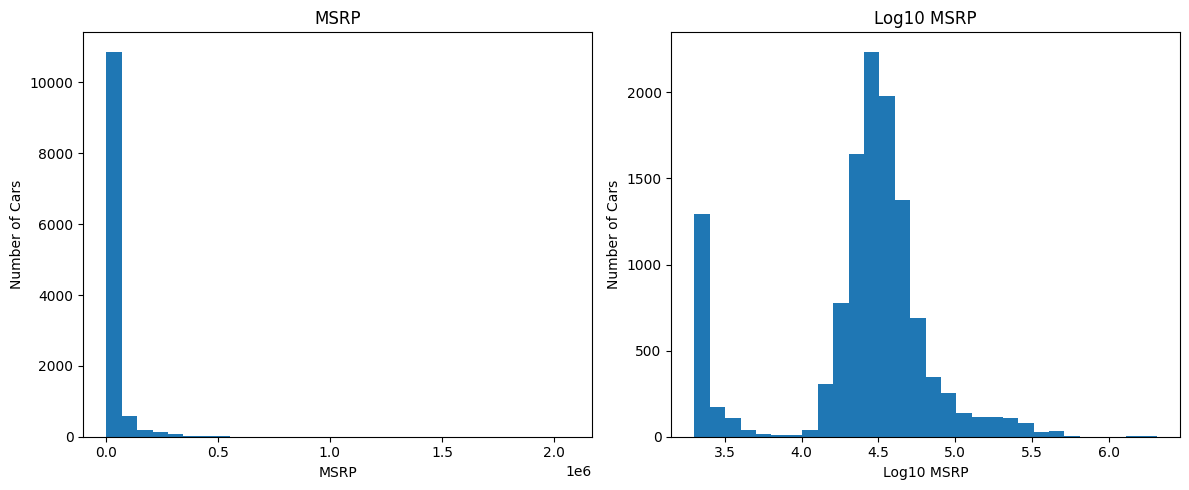

Percent above mean: 27.438307873090483


In [10]:
# a) mean and median
mean_price = clean["msrp"].mean()
median_price = clean["msrp"].median()

print("Mean MSRP:", mean_price)
print("Median MSRP:", median_price)
# b) two histograms side by side (plt.subplots(1, 2))
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(clean["msrp"].dropna(), bins=30)
plt.title("MSRP")
plt.xlabel("MSRP")
plt.ylabel("Number of Cars")

plt.subplot(1, 2, 2)
plt.hist(np.log10(clean["msrp"].dropna()), bins=30)
plt.title("Log10 MSRP")
plt.xlabel("Log10 MSRP")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

# c) share of cars above the mean
percent_above_mean = (clean["msrp"] > mean_price).mean() * 100

print("Percent above mean:", percent_above_mean)

**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [12]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
cars_2017 = df[df["Year"] == 2017]
stats_by_size = cars_2017.groupby("Vehicle Size")["highway MPG"].agg(["mean", "std"])
print(stats_by_size)
# b) z = (value - class mean) / class std
stats = cars_2017.groupby("Vehicle Size")["highway MPG"].agg(["mean", "std"])

civic_z = (42 - stats.loc["Compact", "mean"]) / stats.loc["Compact", "std"]
volvo_z = (34 - stats.loc["Large", "mean"]) / stats.loc["Large", "std"]

print("Civic z-score:", civic_z)
print("Volvo S90 z-score:", volvo_z)

print("Honda Civic z-score:", civic_z)
print("Volvo S90 z-score:", volvo_z)

                   mean        std
Vehicle Size                      
Compact       31.833333  10.697106
Large         22.943158   3.502099
Midsize       30.000000  13.763526
Civic z-score: 0.9504128052192553
Volvo S90 z-score: 3.1572046787829264
Honda Civic z-score: 0.9504128052192553
Volvo S90 z-score: 3.1572046787829264


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

2017 median MSRP: 36647.5
95% bootstrap interval: 35870.0 37650.0


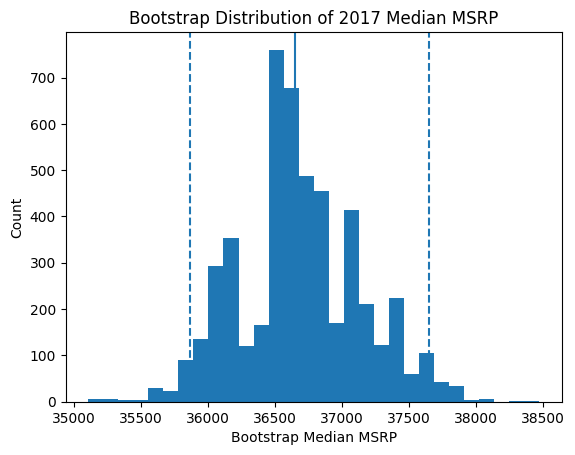

make
Subaru        47
Lincoln       46
Kia           43
Buick         39
Acura         36
Lexus         34
Mitsubishi    29
Infiniti      28
Volvo         25
Porsche       25
Name: count, dtype: int64
Chosen make: Subaru
Number of cars: 47
95% interval: 23995.0 28840.0


In [14]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    medians = []

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))

    return np.array(medians)

# a, b)
cars_2017 = clean[clean["year"] == 2017].dropna(subset=["msrp"])

prices_2017 = cars_2017["msrp"].values

median_2017 = np.median(prices_2017)

print("2017 median MSRP:", median_2017)

boot_medians = bootstrap_median(prices_2017, 5000)

lower = np.percentile(boot_medians, 2.5)
upper = np.percentile(boot_medians, 97.5)

print("95% bootstrap interval:", lower, upper)

plt.hist(boot_medians, bins=30)
plt.axvline(lower, linestyle="--")
plt.axvline(upper, linestyle="--")
plt.axvline(median_2017, linestyle="-")
plt.xlabel("Bootstrap Median MSRP")
plt.ylabel("Count")
plt.title("Bootstrap Distribution of 2017 Median MSRP")
plt.show()

# c)
make_counts = cars_2017["make"].value_counts()

print(make_counts[make_counts < 50].head(10))

small_make = make_counts[make_counts < 50].index[0]

small_make_prices = cars_2017[
    cars_2017["make"] == small_make
]["msrp"].values

small_boot = bootstrap_median(small_make_prices, 5000)

small_lower = np.percentile(small_boot, 2.5)
small_upper = np.percentile(small_boot, 97.5)

print("Chosen make:", small_make)
print("Number of cars:", len(small_make_prices))
print("95% interval:", small_lower, small_upper)

**Answer:**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

a)
H₀: μ ≤ 30 MPG
Hₐ: μ > 30 MPG
One-sided test because we're asking whether the average is over 30.


Number of cars: 522
Mean MPG: 30.582375478927204
Standard deviation: 5.775213077706314


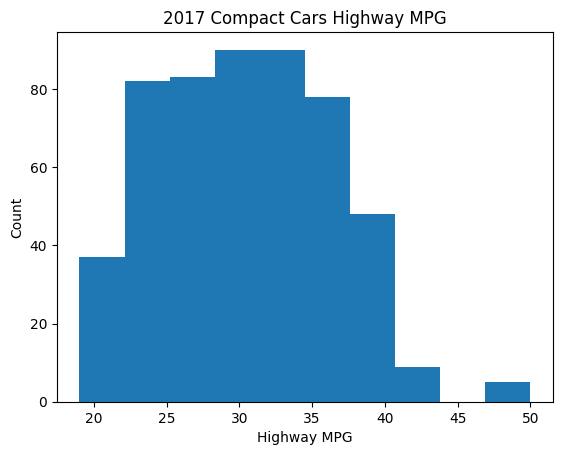


T-statistic: 2.303935517314238
P-value: 0.010809446707730453
Conclusion: Reject H0. There is enough evidence to say that
2017 compact cars average more than 30 MPG.

Number of rows for each Make + Model:
Make       Model          
Toyota     Tacoma             32
Chevrolet  Corvette           24
Nissan     Frontier           22
           370Z               17
Ford       Transit Connect    16
                              ..
Audi       TTS                 1
Ford       Focus RS            1
Lexus      CT 200h             1
Acura      NSX                 1
Ford       Focus ST            1
Length: 84, dtype: int64

Number of unique Make + Model combinations: 84
Model-level mean MPG: 31.426089088510306
Model-level t-statistic: 2.3437068342558636
Model-level p-value: 0.010742186100591957
Conclusion: Reject H0. Even after averaging to one row per model,
there is enough evidence that the average MPG is greater than 30.


In [18]:
from scipy import stats
import matplotlib.pyplot as plt
# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram
q5 = df[(df["Year"] == 2017) & (df["Vehicle Size"] == "Compact") & (df["highway MPG"] <= 50)].copy()
print("\nNumber of cars:", len(q5))
print("Mean MPG:", q5["highway MPG"].mean())
print("Standard deviation:", q5["highway MPG"].std())

plt.hist(q5["highway MPG"], bins=10)
plt.xlabel("Highway MPG")
plt.ylabel("Count")
plt.title("2017 Compact Cars Highway MPG")
plt.show()

# c) one-sample t-test vs 30
test = stats.ttest_1samp(
    q5["highway MPG"],
    30,
    alternative="greater"
)

print("\nT-statistic:", test.statistic)
print("P-value:", test.pvalue)

if test.pvalue < 0.05:
    print("Conclusion: Reject H0. There is enough evidence to say that")
    print("2017 compact cars average more than 30 MPG.")
else:
    print("Conclusion: Fail to reject H0. There is not enough evidence")
    print("to say that 2017 compact cars average more than 30 MPG.")

# d) rows per make+model, then one row per model and retest
counts = q5.groupby(["Make", "Model"]).size()

print("\nNumber of rows for each Make + Model:")
print(counts.sort_values(ascending=False))

model_avg = q5.groupby(["Make", "Model"])["highway MPG"].mean()

model_test = stats.ttest_1samp(
    model_avg,
    30,
    alternative="greater"
)

print("\nNumber of unique Make + Model combinations:", len(model_avg))
print("Model-level mean MPG:", model_avg.mean())
print("Model-level t-statistic:", model_test.statistic)
print("Model-level p-value:", model_test.pvalue)

if model_test.pvalue < 0.05:
    print("Conclusion: Reject H0. Even after averaging to one row per model,")
    print("there is enough evidence that the average MPG is greater than 30.")
else:
    print("Conclusion: Fail to reject H0. After averaging to one row per model,")
    print("there is not enough evidence that the average MPG is greater than 30.")


**Answer:**

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [19]:
# a) compare median MSRP by transmission type
auto = df[df["Transmission Type"] == "AUTOMATIC"]
manual = df[df["Transmission Type"] == "MANUAL"]
print("Q6(a)")
print("Automatic median MSRP:", auto["MSRP"].median())
print("Manual median MSRP:", manual["MSRP"].median())
# b) compare year by transmission type
print("\nQ6(b)")
print("Automatic median year:", auto["Year"].median())
print("Manual median year:", manual["Year"].median())

print("\nAutomatic year range:", auto["Year"].min(), "-", auto["Year"].max())
print("Manual year range:", manual["Year"].min(), "-", manual["Year"].max())
# c) compare 2015-2017 medians overall and within each vehicle_size
# For 2015-17 compacts, test automatic vs manual prices with:
# stats.mannwhitneyu(auto, manual)
recent = df[
    (df["Transmission Type"].isin(["AUTOMATIC", "MANUAL"])) &
    (df["Year"].isin([2015, 2016, 2017]))
]

auto_recent = recent[recent["Transmission Type"] == "AUTOMATIC"]
manual_recent = recent[recent["Transmission Type"] == "MANUAL"]

print("\nQ6(c)")
print("2015–2017 Automatic median MSRP:", auto_recent["MSRP"].median())
print("2015–2017 Manual median MSRP:", manual_recent["MSRP"].median())


print("\nMedian MSRP by Vehicle Size:")
print(
    recent.groupby(["Vehicle Size", "Transmission Type"])["MSRP"].median()
)


compact = recent[recent["Vehicle Size"] == "Compact"]

auto_compact = compact[
    compact["Transmission Type"] == "AUTOMATIC"
]["MSRP"]

manual_compact = compact[
    compact["Transmission Type"] == "MANUAL"
]["MSRP"]

test = stats.mannwhitneyu(
    auto_compact,
    manual_compact
)

print("\n2015–2017 Compact cars:")
print("Automatic median:", auto_compact.median())
print("Manual median:", manual_compact.median())
print("U-statistic:", test.statistic)
print("p-value:", test.pvalue)


Q6(a)
Automatic median MSRP: 32565.0
Manual median MSRP: 18720.0

Q6(b)
Automatic median year: 2015.0
Manual median year: 2008.0

Automatic year range: 1990 - 2017
Manual year range: 1990 - 2017

Q6(c)
2015–2017 Automatic median MSRP: 36732.5
2015–2017 Manual median MSRP: 27090.0

Median MSRP by Vehicle Size:
Vehicle Size  Transmission Type
Compact       AUTOMATIC            25990.0
              MANUAL               26255.0
Large         AUTOMATIC            44540.0
              MANUAL               38395.0
Midsize       AUTOMATIC            37605.0
              MANUAL               26920.0
Name: MSRP, dtype: float64

2015–2017 Compact cars:
Automatic median: 25990.0
Manual median: 26255.0
U-statistic: 346203.0
p-value: 0.0941621665794619


**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [20]:
# a) Welch t-test, 4-door vs 2-door
mpg_cars = df[
    (df["highway MPG"].notna()) &
    (df["Number of Doors"].isin([2, 4]))
].copy()

four_door = mpg_cars[
    mpg_cars["Number of Doors"] == 4
]["highway MPG"].dropna()

two_door = mpg_cars[mpg_cars["Number of Doors"] == 2]["highway MPG"].dropna()

test = stats.ttest_ind(
    four_door,
    two_door,
    equal_var=False
)

difference = four_door.mean() - two_door.mean()

print("4-door mean:", four_door.mean())
print("2-door mean:", two_door.mean())
print("Difference:", difference)
print("p-value:", test.pvalue)
# b) yearly gas cost = miles * price_per_gallon / mpg
miles = 12000
price_per_gallon = 3.50

four_door_cost = miles * price_per_gallon / four_door.mean()
two_door_cost = miles * price_per_gallon / two_door.mean()

savings = two_door_cost - four_door_cost

print("4-door yearly gas cost:", four_door_cost)
print("2-door yearly gas cost:", two_door_cost)
print("Yearly difference:", savings)
# c) simulation
n_sims, hits = 1000, 0

for _ in range(n_sims):

    sample_four = rng.choice(
        four_door,
        30,
        replace=False
    )

    sample_two = rng.choice(
        two_door,
        30,
        replace=False
    )

    result = stats.ttest_ind(
        sample_four,
        sample_two,
        equal_var=False
    )

    if result.pvalue < 0.05:
        hits += 1

fraction_significant = hits / n_sims

print("Fraction significant:", fraction_significant)

4-door mean: 27.431701185202922
2-door mean: 25.35379746835443
Difference: 2.0779037168484926
p-value: 3.08668000886458e-41
4-door yearly gas cost: 1531.075295565535
2-door yearly gas cost: 1656.5565790459073
Yearly difference: 125.48128348037221
Fraction significant: 0.155


**Answer:**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2